# INCT — Benchmark MLP para Burgers

**Etapa 1:** largura da MLP. **Etapa 2:** profundidade com 64 neurônios.

Objetivo: escolher um baseline clássico forte antes das próximas ablações e comparações com MPC. Os gráficos apresentam média ± desvio-padrão entre sementes; não são resultados finais.


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Se o notebook estiver em notebooks/, a raiz é a pasta anterior.
ROOT = Path.cwd()
if not (ROOT / "runs").exists():
    ROOT = ROOT.parent

JOB_ID = "2318"  # Etapa 1: largura da MLP, Burgers
DATA = ROOT / "runs" / "jobs" / JOB_ID / "results" / "burgers"
MODELS = ["mlp_width_8", "mlp_width_16", "mlp", "mlp_width_64", "mlp_width_128"]
LABELS = {"mlp_width_8": "8", "mlp_width_16": "16", "mlp": "32", "mlp_width_64": "64", "mlp_width_128": "128"}

print("Resultados:", DATA)
print("Diretório existe:", DATA.exists())

Resultados: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2318/results/burgers
Diretório existe: True


## 1. Treinamentos concluídos e desempenho

Cada `metrics.json` representa um treinamento concluído. A tabela mostra média e **desvio-padrão entre sementes**, sem misturar experimentos ainda em andamento.

In [10]:
import json

rows = []
for model in MODELS:
    for p in sorted((DATA / model).glob("seed_*/metrics.json")):
        seed = int(p.parent.name.replace("seed_", ""))
        metrics = json.loads(p.read_text())
        rows.append({"model": model, "width": int(LABELS[model]), "seed": seed,
                     "rmse": metrics.get("rmse", np.nan),
                     "relative_l2": metrics.get("relative_l2", np.nan),
                     "parameters": metrics.get("parameters", np.nan)})

df = pd.DataFrame(rows)
if df.empty:
    print("Ainda não existem metrics.json nesta campanha. Confira JOB_ID e a execução PBS.")
else:
    table = (df.groupby("width").agg(
        sementes=("seed", "nunique"), rmse_medio=("rmse", "mean"),
        rmse_dp=("rmse", "std"), l2_medio=("relative_l2", "mean"),
        l2_dp=("relative_l2", "std"),
        parametros=("parameters", "first"))).sort_index()
    display(table.round(6))

,sementes,rmse_medio,rmse_dp,l2_medio,l2_dp,parametros
width,,,,,,
8,10,0.031370,0.013006,0.141700,0.058747,177
16,10,0.019051,0.006868,0.086055,0.031025,609
32,10,0.012052,0.004193,0.054440,0.018940,2241
64,10,0.011649,0.003301,0.052620,0.014911,8577
128,10,0.013252,0.003088,0.059859,0.013951,33537


## 2. RMSE versus número de neurônios

As barras representam **± 1 desvio-padrão** entre as sementes concluídas; isso descreve a dispersão entre execuções, não um intervalo de confiança.

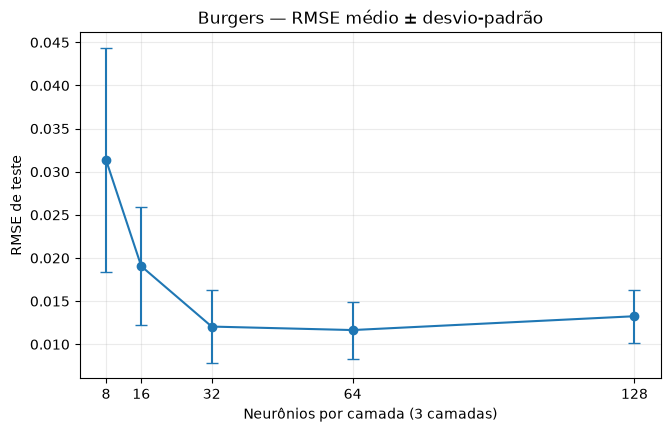

In [11]:
if not df.empty:
    summary = df.groupby("width")["rmse"].agg(["mean", "std", "count"]).sort_index()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.errorbar(summary.index, summary["mean"], yerr=summary["std"].fillna(0),
                marker="o", capsize=4, linewidth=1.5)
    ax.set(xlabel="Neurônios por camada (3 camadas)", ylabel="RMSE de teste",
           title="Burgers — RMSE médio ± desvio-padrão")
    ax.set_xticks(summary.index)
    ax.grid(alpha=0.25)
    plt.show()

## 3. Curvas de convergência

MSE de validação ao longo das épocas: **média ± desvio-padrão entre sementes**. Cada curva inclui apenas históricos que já foram salvos; as bandas podem ficar incompletas enquanto o job executa.

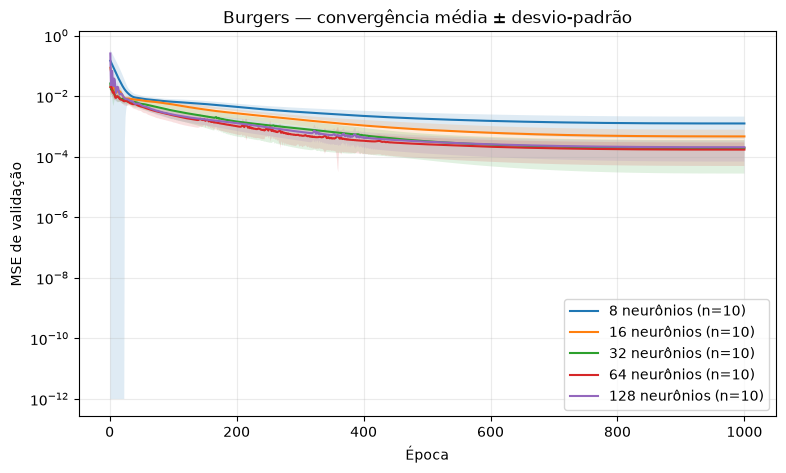

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
found = False
for model in MODELS:
    series = []
    for path in sorted((DATA / model).glob("seed_*/history.csv")):
        h = pd.read_csv(path)
        if {"epoch", "val_mse"}.issubset(h.columns):
            series.append(h.set_index("epoch")["val_mse"].rename(path.parent.name))
    if not series:
        continue
    found = True
    mat = pd.concat(series, axis=1)
    mean = mat.mean(axis=1)
    std = mat.std(axis=1).fillna(0)
    ax.plot(mean.index, mean.clip(lower=1e-12), label=f"{LABELS[model]} neurônios (n={len(series)})")
    ax.fill_between(mean.index, (mean - std).clip(lower=1e-12),
                    (mean + std).clip(lower=1e-12), alpha=0.14)
if found:
    ax.set(yscale="log", xlabel="Época", ylabel="MSE de validação",
           title="Burgers — convergência média ± desvio-padrão")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
else:
    plt.close(fig)
    print("Nenhum history.csv encontrado ainda.")

---

## Etapa 2 — Ablação de profundidade (64 neurônios)

Mesma análise da Etapa 1: tabela de métricas, RMSE por arquitetura e convergência da validação. A configuração com três camadas reutiliza o resultado de 64 neurônios do job 2318.


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "runs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

JOBS = ROOT / "runs" / "jobs"

# Profundidade 3 = MLP de 64 neurônios da Etapa 1.
# Profundidade 1 = job anterior, localizado pelo nome do modelo.
EXPERIMENTS = {
    1: (None, "mlp_64_depth_1"),
    2: ("2320", "mlp_64_depth_2"),
    3: ("2318", "mlp_width_64"),
    4: ("2321", "mlp_64_depth_4"),
    5: ("2322", "mlp_64_depth_5"),
    10: ("2323", "mlp_64_depth_10"),
    15: ("2324", "mlp_64_depth_15"),
    20: ("2325", "mlp_64_depth_20"),
}

def model_dir(depth):
    job_id, name = EXPERIMENTS[depth]
    if job_id is not None:
        return JOBS / job_id / "results" / "burgers" / name
    candidates = sorted(JOBS.glob(f"*/results/burgers/{name}"))
    candidates = [p for p in candidates if list(p.glob("seed_*/metrics.json"))]
    if not candidates:
        return JOBS / "JOB_DEPTH_1_NAO_ENCONTRADO" / "results" / "burgers" / name
    if len(candidates) > 1:
        print("Atenção: mais de um job para profundidade 1:", [p.parts[-4] for p in candidates])
        print("Usando o último caminho ordenado; confira se corresponde à mesma campanha.")
    return candidates[-1]

DATA = {depth: model_dir(depth) for depth in EXPERIMENTS}
for depth, path in DATA.items():
    print(f"{depth} camadas: {path} | existe: {path.exists()}")


1 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2319/results/burgers/mlp_64_depth_1 | existe: True
2 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2320/results/burgers/mlp_64_depth_2 | existe: True
3 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2318/results/burgers/mlp_width_64 | existe: True
4 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2321/results/burgers/mlp_64_depth_4 | existe: True
5 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2322/results/burgers/mlp_64_depth_5 | existe: True
10 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2323/results/burgers/mlp_64_depth_10 | existe: True
15 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2324/results/burgers/mlp_64_depth_15 | existe: True
20 camadas: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2325/results/burgers/mlp_64_depth_20 | existe: True


## 1. Treinamentos concluídos e desempenho

Cada `metrics.json` representa uma semente concluída. A tabela compara **RMSE**, **erro relativo L2** e **número de parâmetros**, usando média e desvio-padrão entre sementes. Não incluímos tempo de treinamento.


In [14]:
import json

rows = []
for depth, folder in DATA.items():
    for p in sorted(folder.glob("seed_*/metrics.json")):
        seed = int(p.parent.name.replace("seed_", ""))
        metrics = json.loads(p.read_text())
        rows.append({
            "depth": depth,
            "seed": seed,
            "rmse": metrics.get("rmse", np.nan),
            "relative_l2": metrics.get("relative_l2", np.nan),
            "parameters": metrics.get("parameters", np.nan),
        })

df_depth = pd.DataFrame(rows)
if df_depth.empty:
    print("Nenhum metrics.json encontrado. Confira os caminhos dos jobs.")
else:
    resumo_depth = (df_depth.groupby("depth").agg(
        sementes=("seed", "nunique"),
        rmse_medio=("rmse", "mean"),
        rmse_dp=("rmse", "std"),
        l2_medio=("relative_l2", "mean"),
        l2_dp=("relative_l2", "std"),
        parametros=("parameters", "first"),
    )).sort_index()
    display(resumo_depth.round(6))


,sementes,rmse_medio,rmse_dp,l2_medio,l2_dp,parametros
depth,,,,,,
1,10,0.037479,0.005345,0.169295,0.024144,257
2,10,0.017220,0.005898,0.077785,0.026642,4417
3,10,0.011649,0.003301,0.052620,0.014911,8577
4,10,0.009642,0.002232,0.043554,0.010081,12737
5,10,0.008143,0.002729,0.036781,0.012329,16897
10,10,0.005232,0.001866,0.023635,0.008427,37697
15,9,0.003896,0.001094,0.017599,0.004942,58497
20,6,0.004642,0.001753,0.020967,0.007920,79297


## 2. RMSE versus número de camadas

As barras representam **± 1 desvio-padrão** entre as sementes concluídas; descrevem a dispersão entre treinamentos, não um intervalo de confiança.


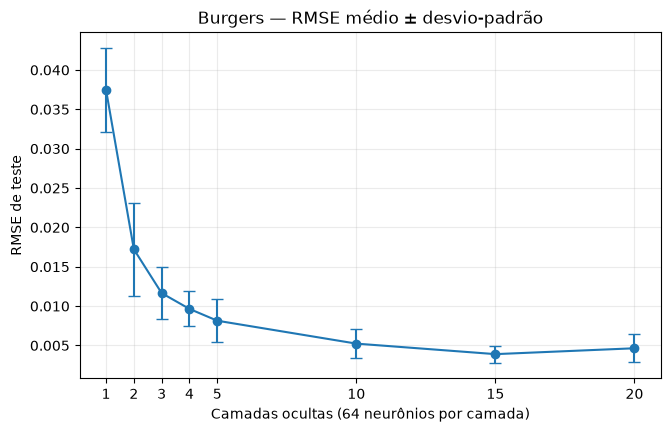

In [17]:
if not df_depth.empty:
    summary = df_depth.groupby("depth")["rmse"].agg(["mean", "std", "count"]).sort_index()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.errorbar(summary.index, summary["mean"], yerr=summary["std"].fillna(0),
                marker="o", capsize=4, linewidth=1.5)
    ax.set(xlabel="Camadas ocultas (64 neurônios por camada)", ylabel="RMSE de teste",
           title="Burgers — RMSE médio ± desvio-padrão")
    ax.set_xticks([1, 2, 3, 4, 5, 10, 15, 20])
    ax.grid(alpha=0.25)
    plt.show()


## 3. Curvas de convergência

MSE de **validação** ao longo das épocas: **média ± desvio-padrão entre sementes**, para cada profundidade. Assim como na Etapa 1, este gráfico utiliza `val_mse` salvo nos históricos; não pressupõe a existência de loss de treinamento.


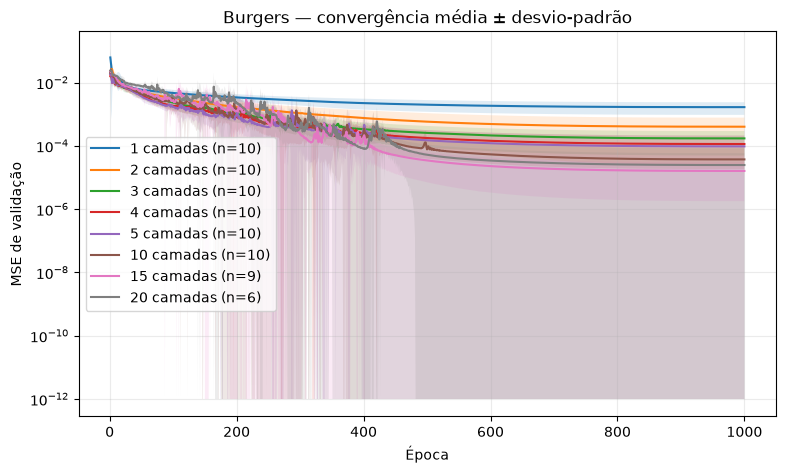

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
found = False
for depth, folder in DATA.items():
    series = []
    for path in sorted(folder.glob("seed_*/history.csv")):
        h = pd.read_csv(path)
        if {"epoch", "val_mse"}.issubset(h.columns):
            series.append(h.set_index("epoch")["val_mse"].rename(path.parent.name))
    if not series:
        continue
    found = True
    mat = pd.concat(series, axis=1)
    mean = mat.mean(axis=1)
    std = mat.std(axis=1).fillna(0)
    ax.plot(mean.index, mean.clip(lower=1e-12), label=f"{depth} camadas (n={len(series)})")
    ax.fill_between(mean.index, (mean - std).clip(lower=1e-12),
                    (mean + std).clip(lower=1e-12), alpha=0.14)
if found:
    ax.set(yscale="log", xlabel="Época", ylabel="MSE de validação",
           title="Burgers — convergência média ± desvio-padrão")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
else:
    plt.close(fig)
    print("Nenhum history.csv encontrado ainda.")


## Próximas etapas

Com largura e profundidade comparadas, continuaremos com learning rate, scheduler e número de épocas **neste mesmo notebook**, um grupo por vez.
